# 01 · Historical backtest: Trinity / Bengen checks

This notebook reproduces the classic safe-withdrawal-rate checks with `firebridgelab`:
a 30-year retirement, a constant **real** (inflation-adjusted) withdrawal of 4% of the
starting portfolio, no other income, no fees, annual rebalancing, across four stock/bond
mixes. For each mix it reports the share of historical start years that never ran out of
money, which start years failed, and the worst cohort's maximum safe withdrawal rate (SWR).

*Educational software, not financial advice.*

## The data, and its limits

The two asset classes used here come from Robert Shiller's monthly *Irrational Exuberance*
file (`ie_data.xls`), read **January to January**:

- **US stocks** (`us_total_market`): S&P Composite real total return (price plus dividends,
  deflated by CPI).
- **US bonds** (`us_agg_bonds`): a 10-year Treasury proxy. The total return is built from the
  10-year yield with a fixed duration of 7 years (income plus a price change of
  −7 × the yield change). It is not an aggregate-bond index.

Limits worth keeping in mind:

- **Prices are monthly averages.** January's figure is the average of January's daily
  closes, so crash years look milder than calendar-year data. 2022 shows −17.4% for
  stocks here, against −23.0% on a December-to-December basis.
- **Cohorts overlap.** A 30-year window starting in 1966 shares 29 years with the one
  starting in 1967. The 126 start years since 1871 amount to roughly five independent 30-year
  histories, so "% of cohorts" is a count, not a probability.
- **One country, one era.** US markets in the 20th century were among the best performing
  in the world. Other countries' histories give lower safe rates.

In [1]:
from dataclasses import replace

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import firebridgelab as rm
from firebridgelab.engine.cohort_windows import cohort_return_sequences

plt.rcParams.update({"figure.dpi": 90, "figure.figsize": (9, 4.2)})
pd.set_option("display.width", 140)
print("firebridgelab", rm.__version__)

firebridgelab 0.1.0


## The plan

`Scenario` is a frozen dataclass, so each variant is built with `dataclasses.replace` from the
library default. Ages 65 to 94 inclusive give 30 years. Every guaranteed-income stream is set
to zero.

In [2]:
base = rm.default_scenario()
stock, bond = base.allocation          # us_total_market, us_agg_bonds
P = 1_000_000.0

def trinity_plan(equity_share, rate=0.04):
    return replace(
        base,
        start_age=65, end_age=94,       # 30 return-years
        initial_portfolio=P,
        annual_spending=rate * P,
        allocation=(replace(stock, weight=equity_share), replace(bond, weight=1 - equity_share)),
        person_a_pension_amount=0.0, person_b_pension_amount=0.0,
        person_a_ss_amount=0.0, person_b_ss_amount=0.0,
        annual_fee=0.0,
        spending_mode="constant",
    )

MIXES = {"25/75": 0.25, "50/50": 0.50, "75/25": 0.75, "100/0": 1.00}

## Per-cohort safe withdrawal rate

The library steps each year with a midpoint convention: the year's withdrawal earns half the
year's return. With constant real spending `s` the balance after year *k* is linear in `s`:

$$B_k = P\,G_k - s\,A_k,\qquad G_k = \prod_{j\le k}(1+r_j),\qquad A_k = A_{k-1}(1+r_k) + (1 + r_k/2)$$

so the largest withdrawal that keeps every year-end balance at or above zero is
$\min_k P\,G_k / A_k$. The function below computes it from the same per-cohort return
sequences the library replays, and the next cell checks it against the library's own
`simulate_historical` and `solve_max_spend`.

In [3]:
def cohort_swr(returns):
    """Max constant real withdrawal, as a fraction of the starting balance."""
    g, a, best = 1.0, 0.0, np.inf
    for r in returns:
        g *= 1 + r
        a = a * (1 + r) + (1 + r / 2)
        best = min(best, g / a)
    return best

rows, swr_by_year = [], {}
for name, eq in MIXES.items():
    plan = trinity_plan(eq)
    years, returns = cohort_return_sequences(plan)
    swr = pd.Series([cohort_swr(r) for r in returns], index=years)
    swr_by_year[name] = swr
    failed = swr.index[swr < 0.04].tolist()

    hist = rm.simulate_historical(plan)                                   # library aggregate
    solved = rm.solve_max_spend(plan, threshold=1.0, mode="historical")   # library solver
    assert hist.depletion_count == len(failed)
    rows.append({
        "mix (stock/bond)": name,
        "cohorts": hist.cohort_count,
        "first–last start": f"{years[0]}–{years[-1]}",
        "failed": len(failed),
        "success %": round(100 * (1 - len(failed) / hist.cohort_count), 1),
        "failing start years": ", ".join(map(str, failed)) or "none",
        "worst SWR %": round(100 * swr.min(), 2),
        "worst start": int(swr.idxmin()),
        "solver, $1k steps": f"${solved.solved_spend:,.0f}",
    })

table = pd.DataFrame(rows).set_index("mix (stock/bond)")
table

,cohorts,first–last start,failed,success %,failing start years,worst SWR %,worst start,"solver, $1k steps"
mix (stock/bond),,,,,,,,
25/75,126,1871–1996,23,81.7,"1899, 1906, 1936, 1937, 1939, 1940, 1941, 1946...",3.34,1966,"$33,000"
50/50,126,1871–1996,6,95.2,"1964, 1965, 1966, 1967, 1968, 1969",3.58,1966,"$35,000"
75/25,126,1871–1996,4,96.8,"1965, 1966, 1968, 1969",3.74,1966,"$37,000"
100/0,126,1871–1996,3,97.6,"1929, 1966, 1969",3.83,1929,"$38,000"


`solve_max_spend` reports the boundary rounded **down** to the nearest $1,000 on a
$1,000,000 portfolio, so it should equal the worst SWR truncated to 0.1%. The assertion above
checks that the closed form and the library agree on which cohorts deplete.

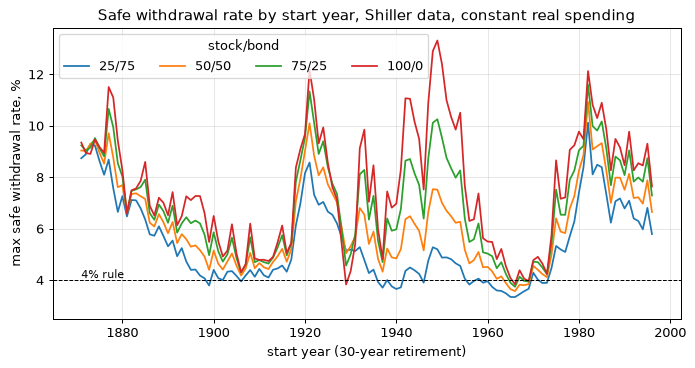

In [4]:
fig, ax = plt.subplots()
for name, swr in swr_by_year.items():
    ax.plot(swr.index, 100 * swr.values, label=name, lw=1.4)
ax.axhline(4.0, color="black", lw=0.8, ls="--")
ax.text(swr.index[0], 4.08, "4% rule", fontsize=9)
ax.set_xlabel("start year (30-year retirement)")
ax.set_ylabel("max safe withdrawal rate, %")
ax.set_title("Safe withdrawal rate by start year, Shiller data, constant real spending")
ax.legend(title="stock/bond", ncol=4, loc="upper left")
ax.set_ylim(2.5, None)
ax.grid(alpha=0.3)
plt.show()

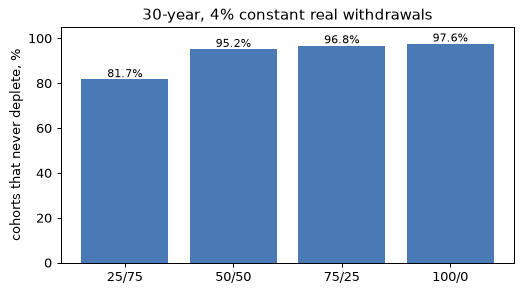

In [5]:
fig, ax = plt.subplots(figsize=(6.5, 3.4))
ax.bar(table.index, table["success %"], color="#4a7ab5")
for i, v in enumerate(table["success %"]):
    ax.text(i, v + 1, f"{v:.1f}%", ha="center", fontsize=9)
ax.set_ylim(0, 105)
ax.set_ylabel("cohorts that never deplete, %")
ax.set_title("30-year, 4% constant real withdrawals")
plt.show()

## How this compares with the published studies

The Trinity study (Cooley, Hubbard and Walz, 1998, inflation-adjusted withdrawals,
1926–1995, S&P 500 and long-term corporate bonds) reported roughly 95% success for a 30-year
4% plan at 50/50 and 98% at 75/25. Bengen (1994, intermediate Treasuries) found a worst-case
rate of about 4.1–4.2% for portfolios between 50% and 75% stocks.

This replay uses different data (Shiller January-to-January returns from 1871, a
duration-7 10-year Treasury proxy) and the midpoint withdrawal convention, so small
differences are expected. The cell below states the result next to the claim in this
repository's README.

In [6]:
s = table["success %"]
w = table["worst SWR %"]
print(f"Success, 50/50: {s['50/50']:.1f}%   75/25: {s['75/25']:.1f}%   (README: 94% to 97%)")
print(f"Worst-cohort SWR, 50/50: {w['50/50']:.2f}%   75/25: {w['75/25']:.2f}%   (README: 3.5–3.7%)")
print("Failing start years at 50/50:", table.loc['50/50', 'failing start years'], "  (README: the 1962–69 cohorts)")

Success, 50/50: 95.2%   75/25: 96.8%   (README: 94% to 97%)
Worst-cohort SWR, 50/50: 3.58%   75/25: 3.74%   (README: 3.5–3.7%)
Failing start years at 50/50: 1964, 1965, 1966, 1967, 1968, 1969   (README: the 1962–69 cohorts)


The worst cohorts are the mid-1960s starts. They are not the ones that met the biggest crash
(1929 hurts only the all-stock mix), but the ones that met a decade and a half of high
inflation: the 1966–1982 period produced poor real returns for both stocks and bonds, early in
the retirement, when the withdrawals matter most. That is sequence-of-returns risk.

Bengen's higher worst-case figure most likely reflects data and timing differences: calendar-year
returns, intermediate rather than 10-year bonds, and end-of-year withdrawals.